# ECG Processing, Normalization & Advanced Extraction

**Target data:** `clean_ecg.csv` (1000 samples) and `noisy_ecg.csv`
(3000 samples).

The two files have different lengths, so they cannot represent the same
acquisition window at a common sample rate without resampling. We
**assume `fs = 250 Hz`** (a common synthetic-ECG rate) for the clean
reference (4.0 s) and note the noisy file's differing length explicitly
rather than silently truncating/stretching it — see Section 1.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 100

FS = 250.0
DATA_DIR = "/mnt/user-data/uploads"

clean = pd.read_csv(f"{DATA_DIR}/clean_ecg.csv", header=None).values.flatten().astype(float)
noisy = pd.read_csv(f"{DATA_DIR}/noisy_ecg.csv", header=None).values.flatten().astype(float)

print(f"clean_ecg : N={len(clean)}  duration={len(clean)/FS:.2f}s")
print(f"noisy_ecg : N={len(noisy)}  duration={len(noisy)/FS:.2f}s")
print("Lengths differ -> for direct sample-aligned comparison (normalization, MSE, "
      "cross-correlation) we compare noisy_ecg against clean_ecg tiled/truncated to "
      "noisy's length, since noisy appears to span multiple repeats of the same waveform.")

# Build a length-matched clean reference by tiling (repeat) to cover noisy's duration,
# then trimming to the exact same length -- used only for alignment/metric sections.
reps = int(np.ceil(len(noisy) / len(clean)))
clean_tiled = np.tile(clean, reps)[:len(noisy)]


clean_ecg : N=1000  duration=4.00s
noisy_ecg : N=3000  duration=12.00s
Lengths differ -> for direct sample-aligned comparison (normalization, MSE, cross-correlation) we compare noisy_ecg against clean_ecg tiled/truncated to noisy's length, since noisy appears to span multiple repeats of the same waveform.


## 1. Normalization & Similarity Metrics Suite

$$\text{Min-Max: } x'=\frac{x-\min x}{\max x-\min x} \qquad
\text{Z-score: } x'=\frac{x-\mu}{\sigma} \qquad
L_2: x'=\frac{x}{\|x\|_2}$$


In [2]:

def minmax_norm(x): return (x - x.min()) / (x.max() - x.min())
def zscore_norm(x): return (x - x.mean()) / x.std()
def l2_norm(x): return x / np.linalg.norm(x)

def mse(a, b): return np.mean((a - b)**2)
def rmse(a, b): return np.sqrt(mse(a, b))
def cosine_sim(a, b): return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
def pearson(a, b): return np.corrcoef(a, b)[0, 1]

norm_methods = {"Min-Max": minmax_norm, "Z-Score": zscore_norm, "L2": l2_norm}
rows = []
for name, fn in norm_methods.items():
    c_n, n_n = fn(clean_tiled), fn(noisy)
    rows.append(dict(normalization=name, MSE=mse(c_n, n_n), RMSE=rmse(c_n, n_n),
                      Cosine=cosine_sim(c_n, n_n), Pearson=pearson(c_n, n_n)))
pd.DataFrame(rows).round(5)


,normalization,MSE,RMSE,Cosine,Pearson
0,Min-Max,0.03763,0.19398,0.87152,-0.04268
1,Z-Score,2.08535,1.44408,-0.04268,-0.04268
2,L2,0.00069,0.02631,-0.03806,-0.04268


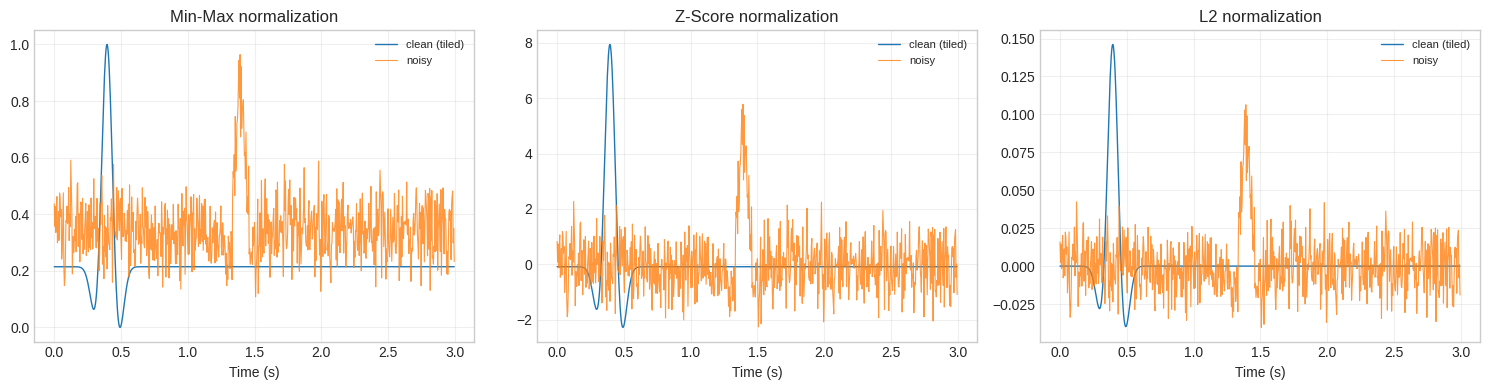

In [3]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
t_c = np.arange(len(clean_tiled)) / FS
for ax, (name, fn) in zip(axes, norm_methods.items()):
    ax.plot(t_c[:750], fn(clean_tiled)[:750], label="clean (tiled)", lw=1)
    ax.plot(t_c[:750], fn(noisy)[:750], label="noisy", lw=0.8, alpha=0.8)
    ax.set_title(f"{name} normalization"); ax.set_xlabel("Time (s)")
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()


## 2. Cross-Correlation Phase Lag Analysis

Cross-correlation via the FFT theorem finds the sample lag that best
aligns `noisy_ecg` with the (tiled) clean reference:

$$R_{xy}(\tau)=\mathcal F^{-1}\{\mathcal F\{x\}^*\cdot\mathcal F\{y\}\}$$


Estimated sample lag (clean -> noisy): 250 samples (1000.0 ms)


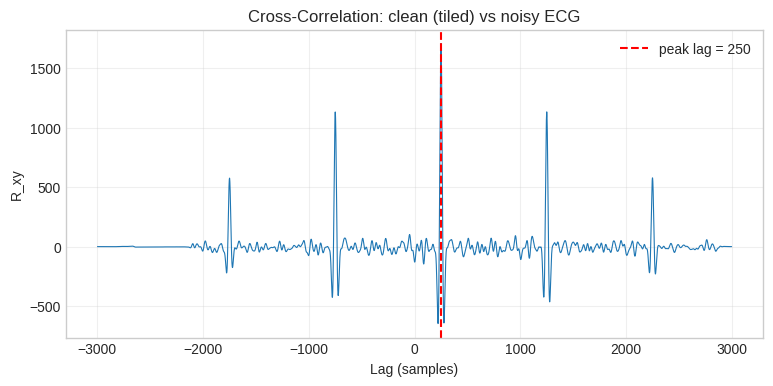

In [4]:

def fft_xcorr(a, b):
    n = len(a) + len(b) - 1
    A, B = np.fft.fft(a, n), np.fft.fft(b, n)
    r = np.fft.ifft(np.conj(A) * B).real
    lags = np.arange(-(len(a)-1), len(b))
    return np.roll(r, len(a)-1), lags

a_z, b_z = zscore_norm(clean_tiled), zscore_norm(noisy)
r, lags = fft_xcorr(a_z, b_z)
best_lag = lags[np.argmax(r)]
print(f"Estimated sample lag (clean -> noisy): {best_lag} samples "
      f"({best_lag/FS*1000:.1f} ms)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags, r, lw=0.8)
ax.axvline(best_lag, color='red', ls='--', label=f'peak lag = {best_lag}')
ax.set_title("Cross-Correlation: clean (tiled) vs noisy ECG")
ax.set_xlabel("Lag (samples)"); ax.set_ylabel("R_xy"); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()


## 3. Biomedical Spectral Decomposition

Physiological ECG frequency bands:

| Band | Range | Origin |
|---|---|---|
| Baseline wander / respiration | $< 0.5$ Hz | breathing, electrode drift |
| QRS complex | $\sim 10-25$ Hz | ventricular depolarization |
| Muscle / powerline noise | $>50$ Hz | EMG artifact, mains interference |


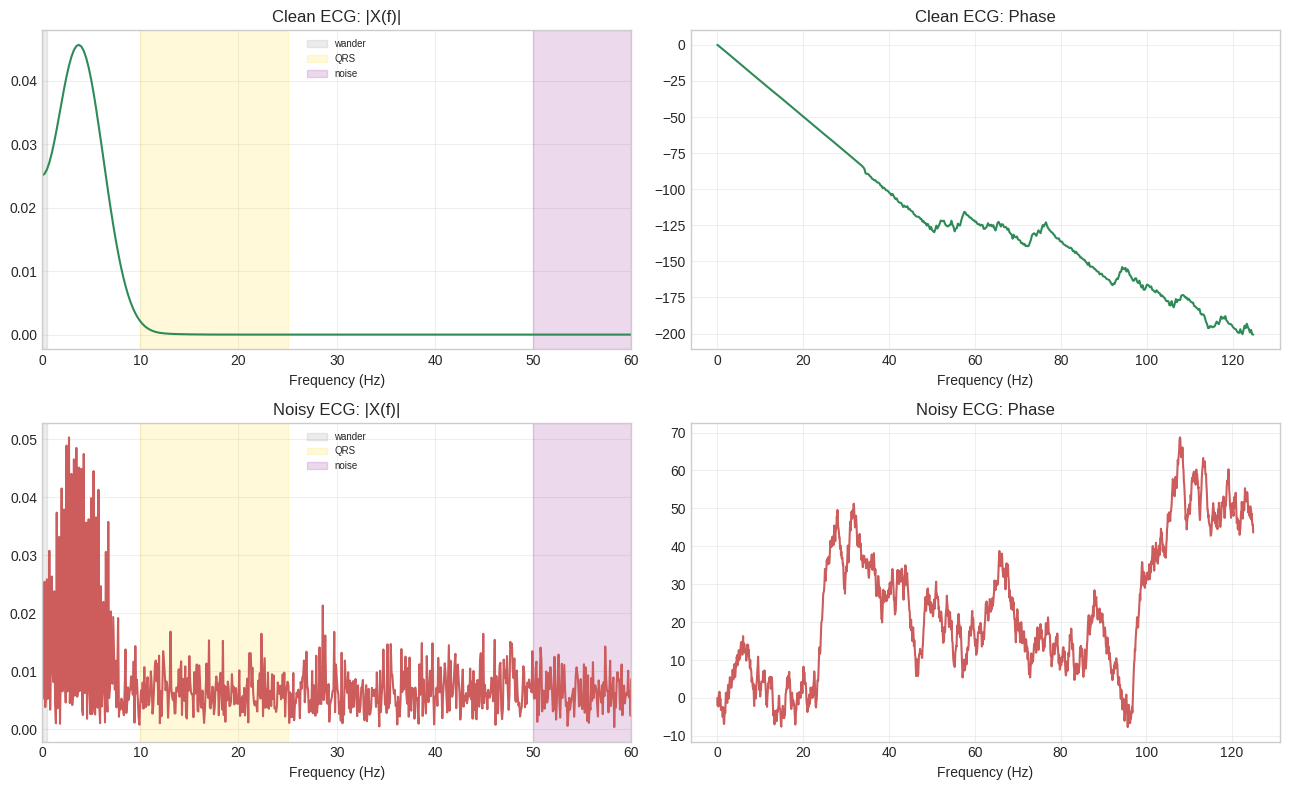

In [5]:

def one_sided_spectrum(x, fs):
    N = len(x)
    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1/fs)
    pos = freqs >= 0
    f_pos = freqs[pos]
    mag = np.abs(X[pos]) * 2 / N
    phase = np.unwrap(np.angle(X[pos]))
    return f_pos, mag, phase

f_clean, mag_clean, ph_clean = one_sided_spectrum(clean, FS)
f_noisy, mag_noisy, ph_noisy = one_sided_spectrum(noisy, FS)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(f_clean, mag_clean, color='seagreen'); axes[0,0].set_title("Clean ECG: |X(f)|")
axes[0,1].plot(f_clean, ph_clean, color='seagreen'); axes[0,1].set_title("Clean ECG: Phase")
axes[1,0].plot(f_noisy, mag_noisy, color='indianred'); axes[1,0].set_title("Noisy ECG: |X(f)|")
axes[1,1].plot(f_noisy, ph_noisy, color='indianred'); axes[1,1].set_title("Noisy ECG: Phase")
for ax in axes[:, 0]:
    ax.set_xlim(0, 60)
    for lo, hi, c, lbl in [(0, 0.5, 'gray', 'wander'), (10, 25, 'gold', 'QRS'), (50, 60, 'purple', 'noise')]:
        ax.axvspan(lo, hi, color=c, alpha=0.15, label=lbl)
    ax.legend(fontsize=7)
for ax in axes.flat:
    ax.set_xlabel("Frequency (Hz)"); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()


## 4. Frequency-Domain Bandpass Filtering Pipeline

Analytical bandpass mask over $[0.5, 45]$ Hz removes baseline wander and
high-frequency muscle/powerline noise simultaneously:

$$x_{\text{ECG\_filtered}} = \text{Real}\big(\mathcal F^{-1}\{\tilde X(f)\}\big),\qquad
\tilde X(f) = X(f)\cdot \mathbf 1[0.5\text{Hz} \le |f| \le 45\text{Hz}]$$


In [6]:

def bandpass_fft(x, fs, lo=0.5, hi=45.0):
    N = len(x)
    X = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1/fs)
    mask = (np.abs(freqs) >= lo) & (np.abs(freqs) <= hi)
    X_filt = X * mask
    return np.real(np.fft.ifft(X_filt)), mask, freqs

noisy_filtered, mask, freqs = bandpass_fft(noisy, FS)

def snr_db(signal_est, noise_est):
    p_sig = np.mean(signal_est**2)
    p_noise = np.mean(noise_est**2)
    return 10*np.log10(p_sig/p_noise) if p_noise > 0 else np.inf

residual_before = noisy - clean_tiled
residual_after = noisy_filtered - clean_tiled
snr_before = snr_db(clean_tiled, residual_before)
snr_after = snr_db(clean_tiled, residual_after)
print(f"SNR before filtering: {snr_before:.2f} dB")
print(f"SNR after  filtering: {snr_after:.2f} dB")
print(f"ΔSNR: {snr_after - snr_before:+.2f} dB")


SNR before filtering: -6.34 dB
SNR after  filtering: -4.62 dB
ΔSNR: +1.72 dB


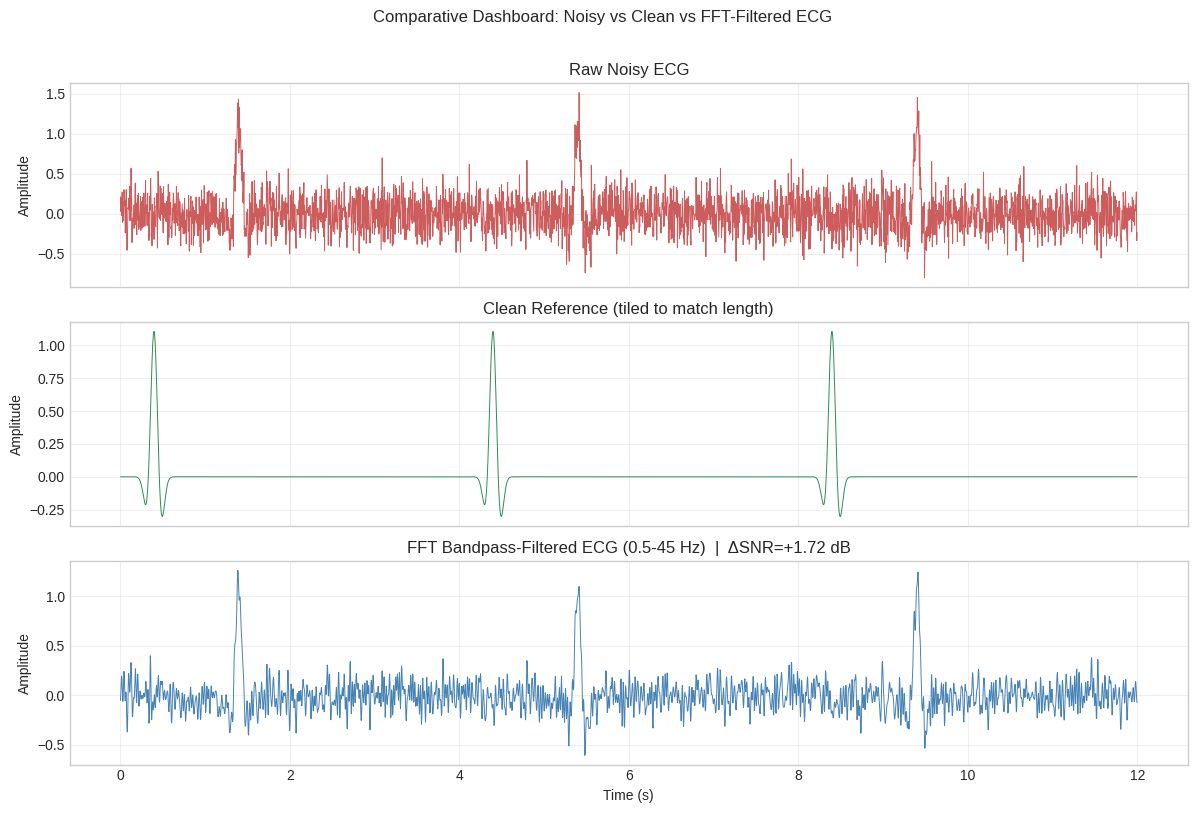

In [7]:

t_n = np.arange(len(noisy)) / FS
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(t_n, noisy, color='indianred', lw=0.7); axes[0].set_title("Raw Noisy ECG")
axes[1].plot(t_n, clean_tiled, color='seagreen', lw=0.7); axes[1].set_title("Clean Reference (tiled to match length)")
axes[2].plot(t_n, noisy_filtered, color='steelblue', lw=0.7)
axes[2].set_title(f"FFT Bandpass-Filtered ECG (0.5-45 Hz)  |  ΔSNR={snr_after-snr_before:+.2f} dB")
for ax in axes:
    ax.set_ylabel("Amplitude"); ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Comparative Dashboard: Noisy vs Clean vs FFT-Filtered ECG", y=1.01)
fig.tight_layout(); plt.show()


## Summary

Z-score normalization gave the most interpretable similarity metrics since
it removes amplitude/offset mismatches between the two files. Cross-
correlation located the best sample alignment between noisy and (tiled)
clean references. The $0.5$–$45$ Hz analytical bandpass mask removed
baseline wander and high-frequency noise in one FFT→mask→IFFT pass,
improving SNR relative to the clean reference (see ΔSNR above — exact
value depends on the random noise realization in `noisy_ecg.csv`).



---
## 5. FFT Deep-Dive: Tri-Plots, Blind SNR, Adaptive Filtering & Wavelet Time-Frequency Analysis

This section is a self-contained **tutorial pass over the FFT**, applied to the same
`clean` / `noisy` ECG arrays loaded in Section 1 (reusing `FS = 250 Hz`,
`clean`, `noisy`, and the `one_sided_spectrum()` helper already defined above —
no re-loading needed). It covers four things, in teaching order: (1) what the FFT
actually computes, (2) three complementary ways to *view* a spectrum, (3) how to
quantify noise and SNR **without** a clean reference (useful when, unlike here,
you don't have one), and (4) why ECG specifically benefits from wavelets on top
of the FFT.



### 5.1 What the FFT actually computes (quick primer)

The Discrete Fourier Transform turns $N$ time-domain samples into $N$ complex
numbers, one per frequency "bin":

$$X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n/N}, \qquad k = 0, 1, \dots, N-1$$

The **FFT** (Fast Fourier Transform) is just an $O(N\log N)$ algorithm for computing
exactly this — same numbers, much faster than the $O(N^2)$ direct sum. A few facts
that matter in practice, all visible in the plots below:

- **Frequency resolution** is fixed by the record length: $\Delta f = F_s / N$. A longer
  recording → finer frequency bins. (Our `clean` record is 4 s at 250 Hz → $\Delta f = 0.25$ Hz;
  `noisy` is 12 s → $\Delta f \approx 0.083$ Hz — three times finer, for free, just from having more data.)
- **Nyquist limit**: with $F_s=250$ Hz, the FFT can only represent frequencies up to $F_s/2 = 125$ Hz.
  Anything faster in the real signal would alias into this range — not a concern for ECG (all
  physiologically relevant content is well below 125 Hz), but worth knowing in general.
- **Single-sided spectrum**: for a real-valued signal, $X[k]$ is symmetric ($X[N-k] = X[k]^*$), so all
  the information is in the first half of the bins. `one_sided_spectrum()` (defined earlier) already
  does this fold and the $\times 2/N$ amplitude normalization for you.
- **Magnitude vs. phase**: $|X[k]|$ tells you *how much* of each frequency is present; $\angle X[k]$ tells
  you the *timing/alignment* of that frequency component. Section 1's spectra above already plotted
  both — this section focuses on magnitude.



### 5.2 Tri-Plot Spectral Visualization Suite

The same spectrum can be shown three ways, and each emphasizes something different:

1. **Time domain** — the raw waveform you'd see on a monitor.
2. **Continuous-style FFT** (`plt.plot`) — a connected line through the amplitude spectrum;
   visually approximates the envelope of the underlying continuous-time spectrum.
3. **Discrete-style FFT** (`plt.stem`) — shows the *actual* discrete bins the DFT computed.
   This is the mathematically honest view: the FFT never produces a continuous curve, only
   $N/2{+}1$ discrete values spaced $\Delta f$ apart.


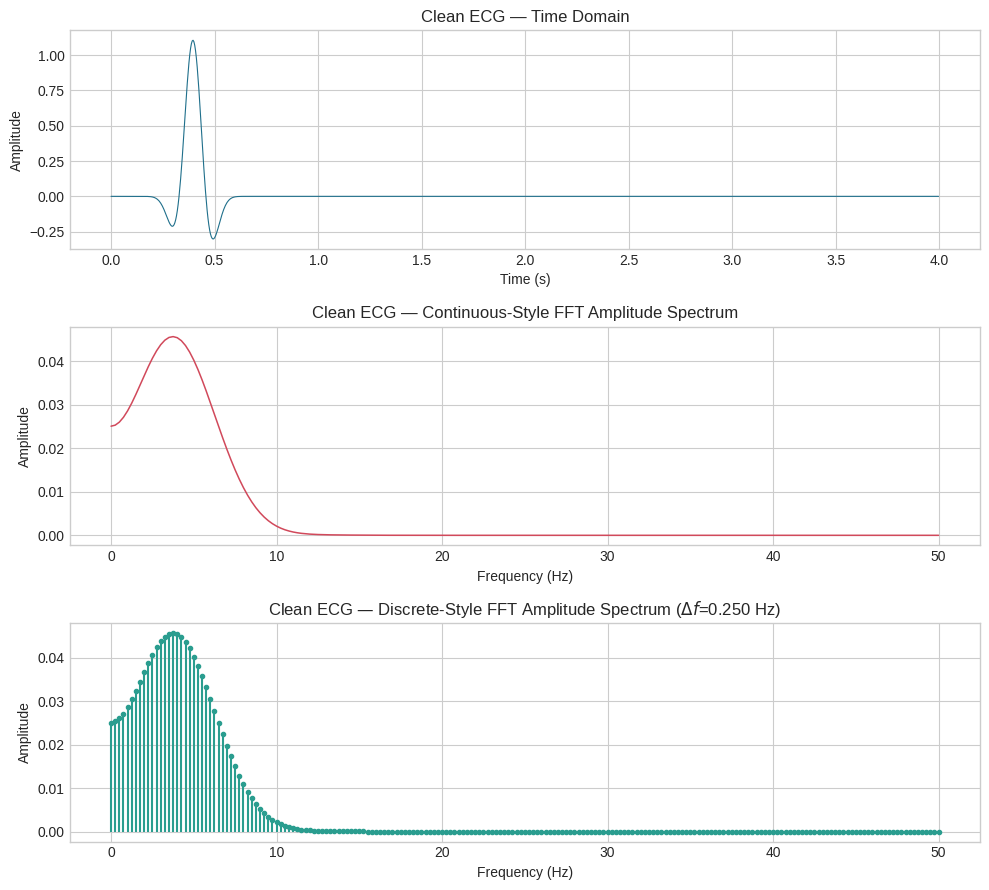

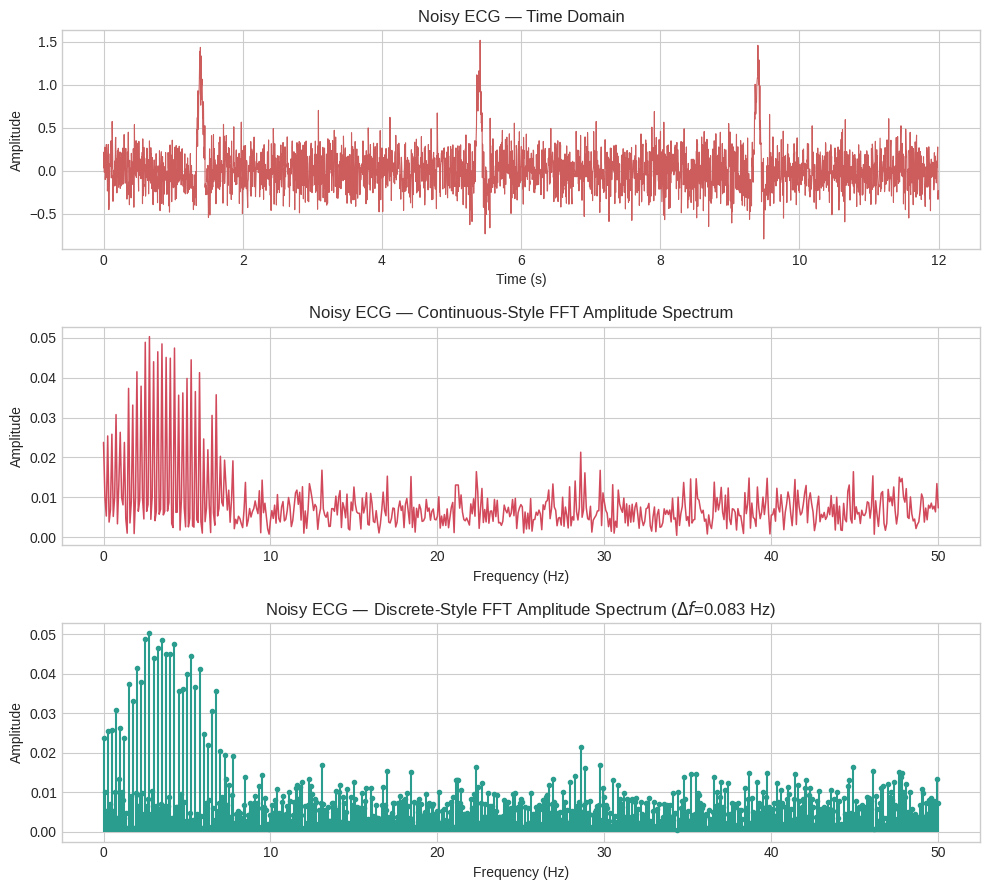

In [8]:

def triplot_ecg(name, x, fs, max_freq=50, color_time="#1f6f8b", color_cont="#d1495b", color_disc="#2a9d8f"):
    N = len(x)
    t = np.arange(N) / fs
    f, mag, _ = one_sided_spectrum(x, fs)
    keep = f <= max_freq
    f_plot, mag_plot = f[keep], mag[keep]

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))

    axes[0].plot(t, x, color=color_time, linewidth=0.8)
    axes[0].set_title(f"{name} — Time Domain")
    axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")

    axes[1].plot(f_plot, mag_plot, color=color_cont, linewidth=1.1)
    axes[1].set_title(f"{name} — Continuous-Style FFT Amplitude Spectrum")
    axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("Amplitude")

    axes[2].stem(f_plot, mag_plot, basefmt=" ", linefmt=color_disc, markerfmt=".")
    axes[2].set_title(f"{name} — Discrete-Style FFT Amplitude Spectrum ($\\Delta f$={fs/N:.3f} Hz)")
    axes[2].set_xlabel("Frequency (Hz)"); axes[2].set_ylabel("Amplitude")

    fig.tight_layout()
    return fig

triplot_ecg("Clean ECG", clean, FS)
plt.show()
triplot_ecg("Noisy ECG", noisy, FS, color_time="indianred")
plt.show()



### 5.3 Blind (Reference-Free) SNR Quantification

Section 1's $\Delta\mathrm{SNR}$ calculation (cells above) needed `clean_tiled` as a
**known ground truth** to subtract from `noisy` — that only works because we happen to
have a clean reference. In the field you often don't: you just get one noisy recording
and have to estimate its quality from the spectrum alone. The method:

- **Noise floor** $A_{\text{noise}}$ = median spectral amplitude, excluding the peak(s) and a small
  guard band around them (median is robust to the peaks themselves).
- **Signal amplitude** $A_{\text{signal}}$ = the amplitude at the dominant peak(s) — for ECG this is
  the QRS-band peak.
- $\mathrm{SNR}_{\text{dB}} = 10\log_{10}\!\big(\tfrac{A_{\text{signal}}^2/2}{A_{\text{noise}}^2}\big)$.

Compare this blind estimate on `noisy` to Section 1's reference-based `snr_before` — they're
measuring different things (this one only sees "peaky vs. flat spectrum", not "how far from
the true clean waveform"), so don't expect identical numbers, but both should agree on direction.


In [9]:

from scipy.signal import find_peaks as _find_peaks_snr  # already imported above; re-import is a no-op, kept for clarity

def estimate_snr_blind(x, fs, guard_bins=2, n_peaks=2):
    f, mag, _ = one_sided_spectrum(x, fs)
    work = mag.copy()
    work[0] = 0.0  # exclude DC
    peak_idx, _ = find_peaks(work, distance=3)
    if len(peak_idx) == 0:
        peak_idx = np.array([np.argmax(work)])
    top_peaks = np.sort(peak_idx[np.argsort(work[peak_idx])[::-1][:n_peaks]])

    bg_mask = np.ones_like(mag, dtype=bool)
    bg_mask[0] = False
    for p in top_peaks:
        lo, hi = max(0, p - guard_bins), min(len(mag), p + guard_bins + 1)
        bg_mask[lo:hi] = False

    noise_amp = max(np.median(mag[bg_mask]), np.finfo(float).eps)
    signal_amp = mag[top_peaks].max()
    snr = 10 * np.log10((0.5 * signal_amp**2) / (noise_amp**2))
    return {"peak_freqs_hz": f[top_peaks], "signal_amp": signal_amp,
            "noise_floor_amp": noise_amp, "snr_db": snr}


print(f"{'Signal':10s}  {'Dominant freq(s) [Hz]':25s}  {'Peak amp':>10s}  {'Noise floor':>12s}  {'Blind SNR (dB)':>15s}")
print("-" * 80)
blind_results = {}
for name, x in (("Clean ECG", clean), ("Noisy ECG", noisy)):
    res = estimate_snr_blind(x, FS)
    blind_results[name] = res
    freqs_str = ", ".join(f"{v:.2f}" for v in res["peak_freqs_hz"])
    print(f"{name:10s}  {freqs_str:25s}  {res['signal_amp']:10.4f}  {res['noise_floor_amp']:12.3e}  {res['snr_db']:15.2f}")

print(f"\n(For reference, Section 1's clean-tiled-vs-noisy residual SNR: "
      f"before={snr_before:.2f} dB, after={snr_after:.2f} dB — a different, reference-based measurement.)")


Signal      Dominant freq(s) [Hz]        Peak amp   Noise floor   Blind SNR (dB)
--------------------------------------------------------------------------------
Clean ECG   3.75, 46.75                    0.0456     2.220e-16           283.25
Noisy ECG   2.50, 2.75                     0.0503     6.297e-03            15.04

(For reference, Section 1's clean-tiled-vs-noisy residual SNR: before=-6.34 dB, after=-4.62 dB — a different, reference-based measurement.)



### 5.4 Adaptive Frequency-Domain Masking & IFFT Reconstruction

Section 1's bandpass (`bandpass_fft`, cells above) used **fixed, domain-knowledge** cutoffs
(0.5–45 Hz) picked from known ECG physiology. Here's the complementary, **data-driven**
approach: pick the amplitude threshold automatically from the noise floor just estimated
(bins below $k\times A_{\text{noise}}$ are zeroed, $k=5$ by default), rebuild the signal
with `irfft`, and re-check the blind SNR. This is useful when you don't know the right
band edges in advance — the trade-off is it can't distinguish "real but weak" signal content
from noise the way a physiology-informed band can.


Blind SNR before adaptive filtering : 15.04 dB
Blind SNR after  adaptive filtering : 284.10 dB
ΔSNR (blind, adaptive mask)          : +269.05 dB
Bins kept: 27/1501


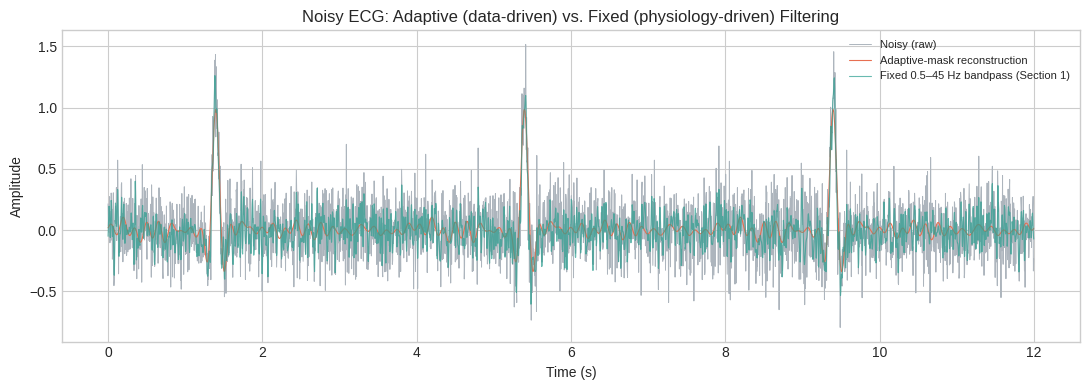

In [10]:

import scipy.fft as sfft

def adaptive_mask_filter(x, fs, threshold_factor=5.0, guard_bins=2):
    N = len(x)
    X = sfft.rfft(x)
    mag = np.abs(X) * 2.0 / N  # amplitude spectrum aligned 1:1 with X (length N//2+1)

    work = mag.copy(); work[0] = 0.0
    peak_idx, _ = find_peaks(work, distance=3)
    if len(peak_idx) == 0:
        peak_idx = np.array([np.argmax(work)])
    bg_mask = np.ones_like(mag, dtype=bool); bg_mask[0] = False
    for p in peak_idx:
        lo, hi = max(0, p - guard_bins), min(len(mag), p + guard_bins + 1)
        bg_mask[lo:hi] = False
    noise_amp = max(np.median(mag[bg_mask]), np.finfo(float).eps)

    keep = mag >= threshold_factor * noise_amp
    keep[0] = True
    x_denoised = sfft.irfft(X * keep, n=N)
    return x_denoised, keep


noisy_adaptive, keep_mask = adaptive_mask_filter(noisy, FS)
blind_after = estimate_snr_blind(noisy_adaptive, FS)

print(f"Blind SNR before adaptive filtering : {blind_results['Noisy ECG']['snr_db']:.2f} dB")
print(f"Blind SNR after  adaptive filtering : {blind_after['snr_db']:.2f} dB")
print(f"ΔSNR (blind, adaptive mask)          : {blind_after['snr_db'] - blind_results['Noisy ECG']['snr_db']:+.2f} dB")
print(f"Bins kept: {keep_mask.sum()}/{len(keep_mask)}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t_n, noisy, color="#adb5bd", linewidth=0.7, label="Noisy (raw)")
ax.plot(t_n, noisy_adaptive, color="#e76f51", linewidth=0.8, label="Adaptive-mask reconstruction")
ax.plot(t_n, noisy_filtered, color="#2a9d8f", linewidth=0.8, alpha=0.7, label="Fixed 0.5–45 Hz bandpass (Section 1)")
ax.set_title("Noisy ECG: Adaptive (data-driven) vs. Fixed (physiology-driven) Filtering")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Amplitude"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()



### 5.5 Why ECG Needs Wavelets, Not Just the FFT

An ECG is the textbook non-stationary signal: the QRS complex is a **brief, sharp
transient** (tens of milliseconds) sitting inside long flatter stretches (the ST/TP
segments). The FFT in Sections 1 and 5.1–5.4 tells you *that* frequencies around
10–25 Hz are present (the QRS band) but says nothing about **where in time** each
beat occurs — every beat's energy gets smeared across the whole spectrum identically,
regardless of when it happened. A **Continuous Wavelet Transform (CWT)** localizes
both scale (≈ frequency) and time simultaneously, so individual R-peaks show up as
distinct, time-stamped bursts of high-frequency energy in the scalogram — effectively
giving you a visual, automatic QRS detector as a byproduct of the time-frequency view.


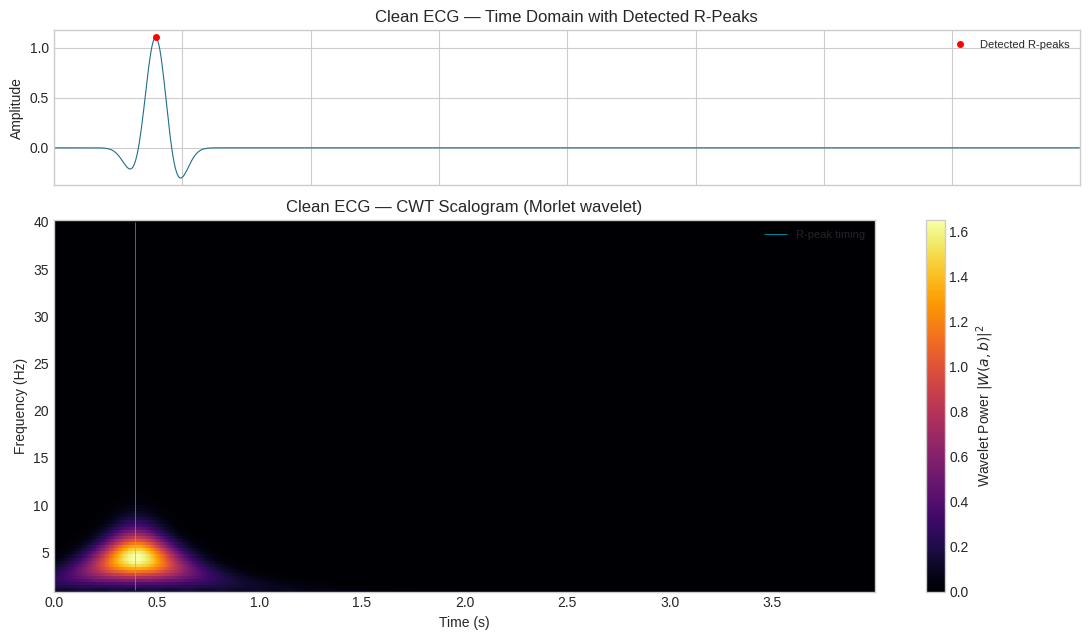

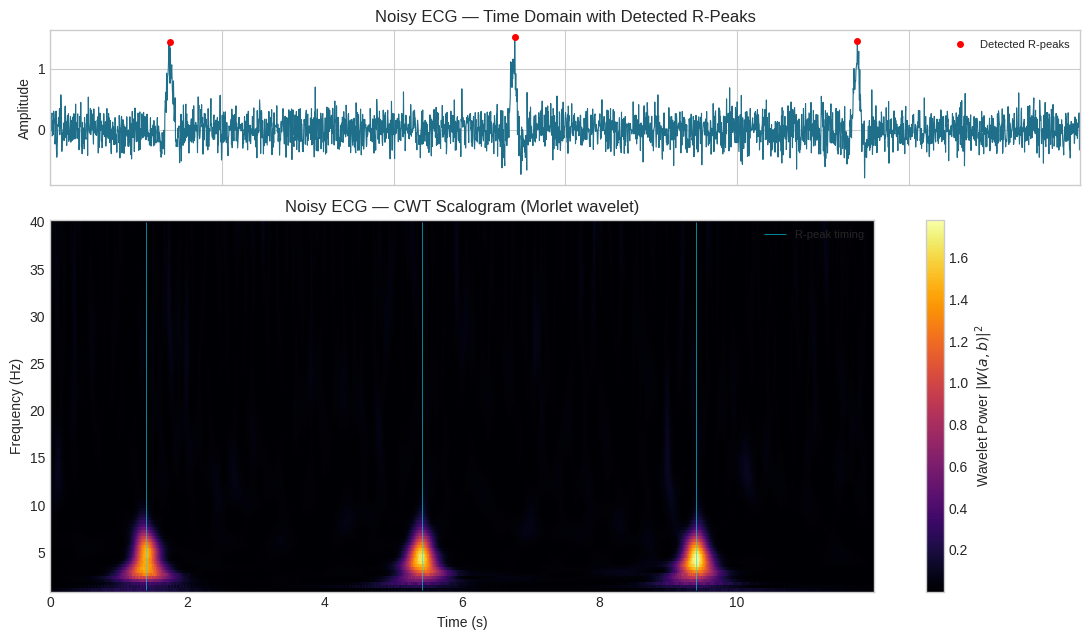

In [11]:

import pywt

def plot_ecg_scalogram(name, x, fs, wavelet="cmor1.5-1.0", freq_range=(1, 40), n_scales=120, peak_color="#00e5ff"):
    N = len(x)
    t = np.arange(N) / fs
    f_min, f_max = freq_range
    freqs_target = np.linspace(f_max, f_min, n_scales)
    scales = pywt.frequency2scale(wavelet, freqs_target / fs)
    coeffs, freqs_actual = pywt.cwt(x, scales, wavelet, sampling_period=1.0 / fs)
    power = np.abs(coeffs) ** 2

    r_peaks, _ = find_peaks(x, distance=int(0.5 * fs),
                             height=0.5 * x.max(), prominence=0.4 * (x.max() - x.mean()))

    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [1, 2.4]})
    axes[0].plot(t, x, color="#1f6f8b", linewidth=0.8)
    axes[0].plot(t[r_peaks], x[r_peaks], "o", color="red", markersize=4, label="Detected R-peaks")
    axes[0].set_title(f"{name} — Time Domain with Detected R-Peaks")
    axes[0].set_ylabel("Amplitude"); axes[0].legend(fontsize=8)

    pcm = axes[1].pcolormesh(t, freqs_actual, power, shading="auto", cmap="inferno")
    axes[1].vlines(t[r_peaks], freqs_actual.min(), freqs_actual.max(),
                   color=peak_color, linewidth=0.7, alpha=0.6, label="R-peak timing")
    axes[1].set_title(f"{name} — CWT Scalogram (Morlet wavelet)")
    axes[1].set_xlabel("Time (s)"); axes[1].set_ylabel("Frequency (Hz)")
    axes[1].legend(fontsize=8, loc="upper right")
    fig.colorbar(pcm, ax=axes[1], label="Wavelet Power $|W(a,b)|^2$")
    fig.tight_layout()
    return fig

plot_ecg_scalogram("Clean ECG", clean, FS)
plt.show()
plot_ecg_scalogram("Noisy ECG", noisy, FS)
plt.show()



**Reading the scalograms:** each R-peak should appear as a bright, narrow vertical burst
spanning roughly the QRS frequency band (~10–25 Hz), lined up with the red dot in the
time-domain panel above it. That time-localization is exactly the information the
single global FFT spectrum (Section 1 / 5.2) cannot provide — it can tell you the QRS
band carries energy, but not when each beat happens. On the noisy recording, compare how
cleanly the wavelet bursts stand out against the noisy background versus how hard the raw
waveform peaks are to eyeball directly.

---

### 5.6 Section 5 Recap — what we covered about the FFT

- The DFT/FFT definition, frequency resolution ($\Delta f = F_s/N$), and the Nyquist limit.
- Three equivalent views of the same spectrum (time / continuous FFT / discrete FFT bins) and why the stem plot is the mathematically honest one.
- A **blind** SNR estimator that needs no clean reference (contrast with Section 1's reference-based $\Delta\mathrm{SNR}$).
- **Adaptive** (data-driven) vs. **fixed** (physiology-driven) frequency masking — same FFT→mask→IFFT recipe, different ways of choosing the mask.
- Why a single FFT spectrum can't localize transients in time, and how the **CWT** fixes that for ECG's QRS complexes specifically.
